In [1]:
import sys
import os
import math
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.decomposition import PCA


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/fly-2023-schaffer/src/manifold/../../../../utils/train_utils.py'>

In [3]:
dims = 3

read_ids = list(range(0, 12+1))
# read_ids = [0,	# paper
# 			1,	# nice states
# 			2,	# nice manifold
# 			5,	# variety
# 			6,	# nice quiescence
# 			7,	# nice states
# 			9,	# nice heatmap
# 			11]	# variety
# read_ids = [0]
plot_id = 0

In [4]:
# read

path = os.path.join(read_utils.get_data_path(), 'brain')
(file_ids, filenames,
 traces,
 states, markers) = read_utils.get_datas(path, read_ids)

# # clear nan values
# for i in range(len(file_ids)):
# 	mask = markers[i].notna().all(axis=1)
#
# 	traces[i] = traces[i][mask]
# 	markers[i] = markers[i][mask]
# 	states[i] = states[i][mask]
#
# 	#filenames[i] = filenames[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

In [5]:
# prep

def highpass_butter(x, fs, cutoff_hz, order=4, axis=0):
    return sp.signal.sosfiltfilt(sp.signal.butter(order, cutoff_hz, btype='highpass', fs=fs, output='sos'), x, axis=axis)

sampling_rates = [read_utils.get_sampling_rate(os.path.join(path, filenames[file_ids.index(file_id)])) for file_id in file_ids]

# traces = [pd.DataFrame(highpass_butter(trace.values, sr, 1 / 100), columns=trace.columns) for trace, sr in zip(traces, sampling_rates)]

# markers_grad = [pd.DataFrame(np.gradient(marker.values, axis=0), columns=marker.columns) for marker in markers]

In [6]:
plot_idx = file_ids.index(plot_id)

In [7]:
for trace, sr in zip(traces, sampling_rates):
	print(f'Recording Length:\t\t\t{int(trace.shape[0] // sr // 60):d}m{(trace.shape[0] // sr % 60):2f}s')
	print(f'Corresponding cutoff f:\t\t{int(trace.shape[0] // sr / 4 // 60):d}m{(trace.shape[0] // sr / 4 % 60):2f}s\n')

Recording Length:			14m27.000000s
Corresponding cutoff f:		3m36.750000s

Recording Length:			29m29.000000s
Corresponding cutoff f:		7m22.250000s

Recording Length:			14m29.000000s
Corresponding cutoff f:		3m37.250000s

Recording Length:			9m29.000000s
Corresponding cutoff f:		2m22.250000s

Recording Length:			24m59.000000s
Corresponding cutoff f:		6m14.750000s

Recording Length:			29m30.000000s
Corresponding cutoff f:		7m22.500000s

Recording Length:			24m28.000000s
Corresponding cutoff f:		6m7.000000s

Recording Length:			19m30.000000s
Corresponding cutoff f:		4m52.500000s

Recording Length:			19m29.000000s
Corresponding cutoff f:		4m52.250000s

Recording Length:			14m29.000000s
Corresponding cutoff f:		3m37.250000s

Recording Length:			29m29.000000s
Corresponding cutoff f:		7m22.250000s

Recording Length:			24m29.000000s
Corresponding cutoff f:		6m7.250000s

Recording Length:			14m30.000000s
Corresponding cutoff f:		3m37.500000s



In [8]:
# traces = [pd.DataFrame(highpass_butter(trace.values, sr, 1 / (trace.shape[0] // sr / 4)), columns=trace.columns) for trace, sr in zip(traces, sampling_rates)]
traces = [pd.DataFrame(highpass_butter(trace.values, sr, 1 / 500), columns=trace.columns) for trace, sr in zip(traces, sampling_rates)]

In [9]:
(modes_manifold,
 recos_manifold,
 loads_pca_man,
 vars_expl_mans) = train_utils.get_manifolds_pca(traces, zscore=False,
												 n_pc=dims)

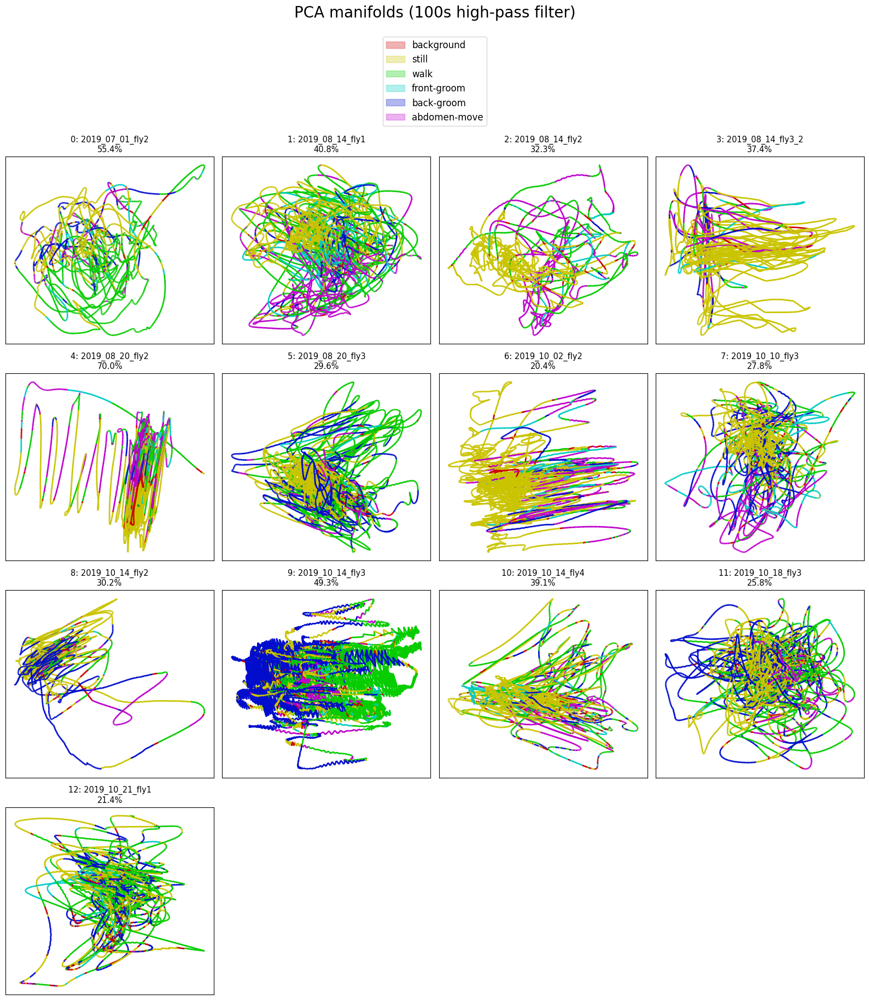

36.9%


In [10]:
save = False
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
						  modes_manifold, states,
						  [vx[:2] for vx in vars_expl_mans], None,
						  title='PCA manifolds (100s high-pass filter)', top_space=2.5,
						  save_path=f'../../out/plots/manifolds/{dims}-dim-PCA' if save else None)

In [11]:
# plot_utils.plot_manifolds_3d([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
# 							 modes_manifold, states,
# 							 [vx[:3] for vx in vars_expl_mans], None,
# 							 title='PCA manifolds (100s high-pass filter)', top_space=3,
# 							 save_path=f'../../out/plots/manifolds/{dims}-dim-PCA_3d' if save else None)

In [12]:
traces_manifolds_indices = [np.argsort(xloads_pca_man[0, :])[::-1] for xloads_pca_man in loads_pca_man]

traces_sorted = [t.iloc[:, t_man_idx.tolist()] for t, t_man_idx in zip(traces, traces_manifolds_indices)]

# traces_manifolds_sorted = [t_man.iloc[:, t_man_idx.tolist()] for t_man, t_man_idx in zip(recos_manifold, traces_manifolds_indices)]
#
# traces_residuals = [pd.DataFrame(t.values - t_rec.values, columns=t.columns) for t, t_rec in zip(traces, recos_manifold)]
#
# traces_residuals_sorted_by_manifold = [t_res.iloc[:, t_man_idx.tolist()] for t_res, t_man_idx in zip(traces_residuals, traces_manifolds_indices)]

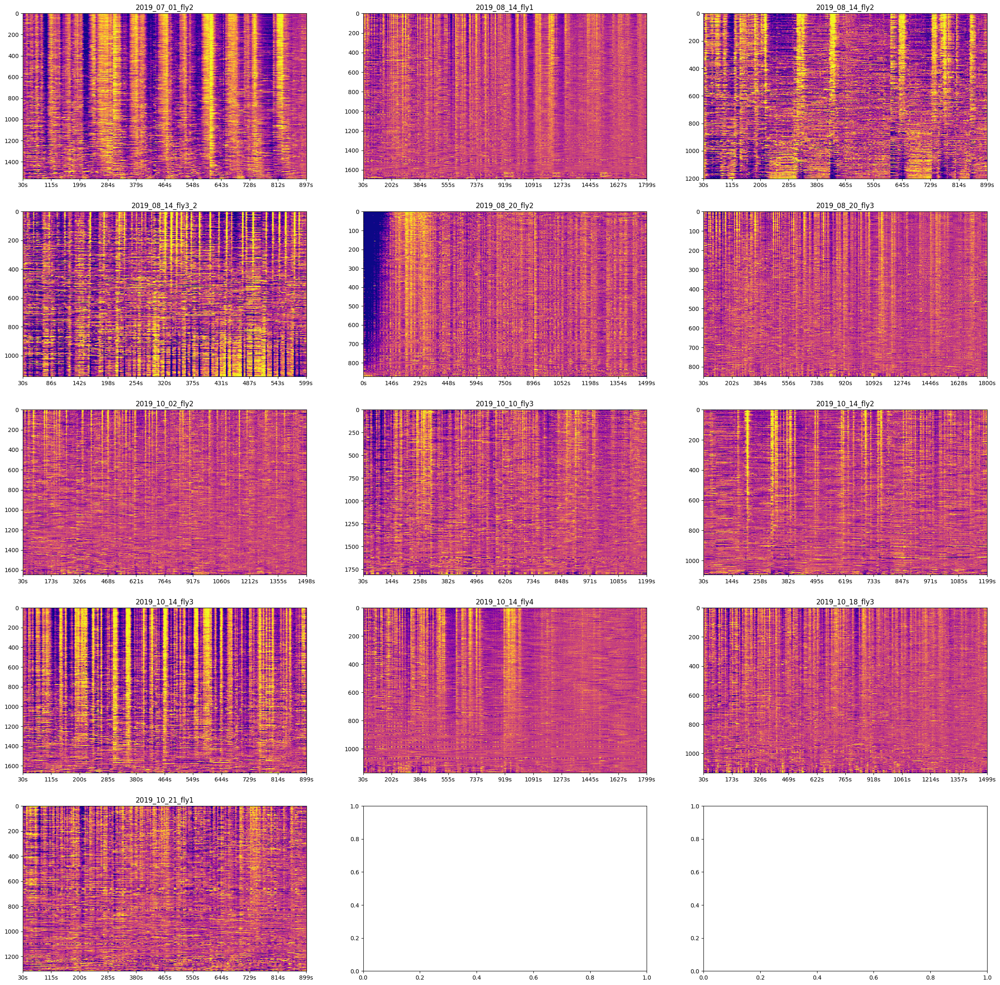

In [13]:
plots_per_row = 3
fig, axes = plt.subplots(math.ceil(len(traces) / plots_per_row), plots_per_row, figsize=(plots_per_row * 10, math.ceil(len(traces) / plots_per_row) * 6))
for i, file_id in enumerate(file_ids):
	ax = axes[i // plots_per_row, i % plots_per_row]

	file_idx = file_ids.index(file_id)
	trace = traces_sorted[file_ids.index(file_id)]

	heatmap = np.clip(trace.values.T, -0.015, 0.015)
	ax.imshow(heatmap,
			  aspect='auto', interpolation='nearest', cmap='plasma')

	timestamps = read_utils.get_timestamps(os.path.join(path, filenames[file_idx]))

	ax.set_xticks(np.arange(0, trace.values.shape[0], trace.values.shape[0] // 10))
	ax.set_xticklabels([f'{ts:.0f}s' for ts in timestamps[::len(timestamps) // 10]])

	ax.set_title(f'{file_id}: {filenames[file_idx]}', fontsize=12)